# Camelyon17 and the Joint Camelyon–SEER Model

## Image dataset, shared architecture and development results

This notebook documents the Camelyon17-WILDS image component and the joint hard-parameter-sharing model trained with Camelyon17 and SEER.

The two datasets are unpaired and are not merged row by row. They have separate encoders and prediction heads but update a common shared representation during alternating training steps.

### Camelyon prediction target

Each input is a 96 × 96 histopathology image patch taken from a breast-cancer lymph-node slide.

- **Class 0:** no metastatic tumour tissue in the labelled central region.
- **Class 1:** metastatic tumour tissue in the labelled central region.

Class 0 does not mean that the patient is cancer-free. It only describes the labelled region of the image patch.

All results shown here are development results. The Camelyon `ood_test` and SEER `temporal_test` splits remain locked.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from PIL import Image

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
FIGURES_DIR = PROJECT_ROOT / "artifacts" / "figures"
CONFIG_DIR = PROJECT_ROOT / "configs"

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 1. Dataset structure and hospital splits

Camelyon17-WILDS separates hospitals to measure generalisation under distribution shift.

- Training and internal validation use hospitals already represented during model development.
- OOD validation uses a different hospital for model selection.
- OOD test uses another unseen hospital and remains locked for final evaluation.

The split design evaluates whether the model transfers across hospital-specific staining and scanning conditions.

In [2]:
camelyon_summary = pd.read_csv(
    METRICS_DIR / "eda_split_summary.csv"
)

camelyon_split_names = {
    "train": "Training",
    "id_val": "Internal validation",
    "ood_val": "OOD validation",
    "ood_test": "OOD test — locked",
}

camelyon_table = (
    camelyon_summary.assign(
        split=camelyon_summary["split"].map(
            camelyon_split_names
        )
    )
    .rename(
        columns={
            "split": "Split",
            "patches": "Patches",
            "non_tumor": "Class 0",
            "tumor": "Class 1",
            "tumor_percent": "Class 1 (%)",
            "centers": "Hospital centres",
            "patients": "Patients",
            "slides": "Slides",
        }
    )
    [
        [
            "Split",
            "Patches",
            "Class 0",
            "Class 1",
            "Class 1 (%)",
            "Hospital centres",
            "Patients",
            "Slides",
        ]
    ]
)

camelyon_table.style.format(
    {
        "Patches": "{:,.0f}",
        "Class 0": "{:,.0f}",
        "Class 1": "{:,.0f}",
        "Class 1 (%)": "{:.2f}",
        "Patients": "{:,.0f}",
        "Slides": "{:,.0f}",
    }
).hide(axis="index")

Split,Patches,Class 0,Class 1,Class 1 (%),Hospital centres,Patients,Slides
Training,"302,436","151,046","151,390",50.06,"0,3,4",26,30
Internal validation,"33,560","16,952","16,608",49.49,"0,3,4",26,30
OOD validation,"34,904","17,452","17,452",50.00,1,8,10
OOD test — locked,"85,054","42,527","42,527",50.00,2,9,10


## 2. Histopathology image examples

The patches contain haematoxylin-and-eosin-stained lymph-node tissue. Differences in colour, staining intensity, tissue density and scanner characteristics can vary across hospitals and create domain shift.

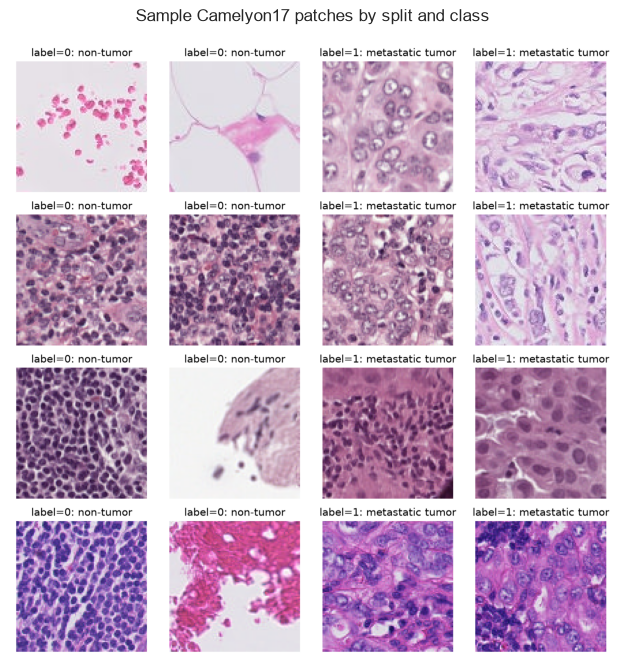

In [3]:
sample_patches = Image.open(
    FIGURES_DIR / "eda_sample_patches.png"
)

plt.figure(figsize=(14, 8))
plt.imshow(sample_patches)
plt.axis("off")
plt.title(
    "Sample Camelyon17 patches by split and class",
    pad=15,
)
plt.show()

### Colour-distribution shift

A development-only sample audit compares average RGB intensity across the training, internal-validation and OOD-validation splits. Large colour differences provide direct evidence that the unseen hospital has a different staining distribution.

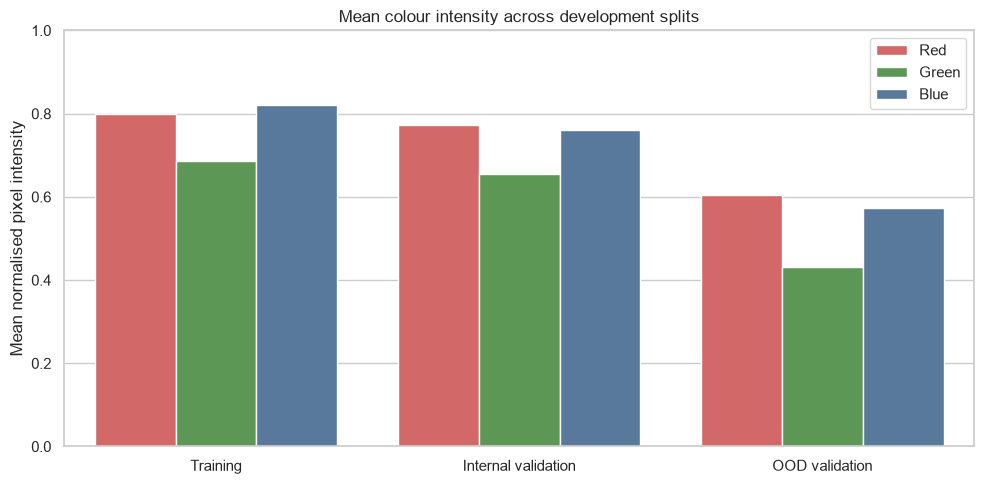

In [4]:
image_statistics = pd.read_csv(
    METRICS_DIR
    / "eda_image_sample_statistics.csv"
)

development_statistics = image_statistics[
    image_statistics["split"].isin(
        ["train", "id_val", "ood_val"]
    )
].copy()

development_statistics["Split"] = (
    development_statistics["split"].map(
        camelyon_split_names
    )
)

rgb_statistics = development_statistics.melt(
    id_vars="Split",
    value_vars=[
        "red_mean",
        "green_mean",
        "blue_mean",
    ],
    var_name="Channel",
    value_name="Mean intensity",
)

rgb_statistics["Channel"] = rgb_statistics[
    "Channel"
].map(
    {
        "red_mean": "Red",
        "green_mean": "Green",
        "blue_mean": "Blue",
    }
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=rgb_statistics,
    x="Split",
    y="Mean intensity",
    hue="Channel",
    palette={
        "Red": "#E45756",
        "Green": "#54A24B",
        "Blue": "#4C78A8",
    },
)

plt.ylim(0, 1)
plt.title(
    "Mean colour intensity across development splits"
)
plt.ylabel("Mean normalised pixel intensity")
plt.xlabel("")
plt.legend(title="")

plt.tight_layout()
plt.show()

## 3. Joint model architecture

The system is one multi-task model with two input paths. It does not require paired image and SEER records.

```text
Camelyon image
      ↓
DenseNet121 image encoder
      ↓
Image projector: 1024 → 256 → 128
      ↓
                              Shared trunk: 128 → 64 → 32
      ↑                                      ↓
SEER projector: 256 → 128              Separate binary heads
      ↑                               ↙                       ↘
SEER neural encoder              Patch metastasis          N0 versus N+
      ↑
Numeric and categorical clinical inputs

In [5]:
with (
    CONFIG_DIR / "joint_model_v2.json"
).open("r", encoding="utf-8") as file:
    joint_config = json.load(file)

image_path = joint_config["image_path"]
tabular_path = joint_config["tabular_path"]
shared_path = joint_config["shared_path"]

architecture_table = pd.DataFrame(
    [
        {
            "Component": "Image input",
            "Configuration": (
                f"{image_path['input_height']} × "
                f"{image_path['input_width']} × "
                f"{image_path['input_channels']}"
            ),
        },
        {
            "Component": "Image encoder",
            "Configuration": (
                "DenseNet121, ImageNet initialisation, "
                "all layers fine-tuned"
            ),
        },
        {
            "Component": "Image projector",
            "Configuration": (
                f"{image_path['encoder_output_dimension']} → "
                f"{image_path['projector_hidden_dimension']} → "
                f"{image_path['projector_output_dimension']}"
            ),
        },
        {
            "Component": "Tabular inputs",
            "Configuration": (
                f"{len(tabular_path['numeric_features'])} numeric and "
                f"{len(tabular_path['categorical_features'])} "
                "categorical features"
            ),
        },
        {
            "Component": "Tabular encoder",
            "Configuration": "256 → 256",
        },
        {
            "Component": "Tabular projector",
            "Configuration": (
                f"256 → "
                f"{tabular_path['projector_output_dimension']}"
            ),
        },
        {
            "Component": "Shared trunk",
            "Configuration": (
                f"{shared_path['input_dimension']} → "
                f"{shared_path['hidden_dimension']} → "
                f"{shared_path['output_dimension']}"
            ),
        },
        {
            "Component": "Prediction heads",
            "Configuration": (
                "Separate 32 → 1 image and tabular heads"
            ),
        },
    ]
)

architecture_table.style.hide(axis="index")

Component,Configuration
Image input,96 × 96 × 3
Image encoder,"DenseNet121, ImageNet initialisation, all layers fine-tuned"
Image projector,1024 → 256 → 128
Tabular inputs,2 numeric and 13 categorical features
Tabular encoder,256 → 256
Tabular projector,256 → 128
Shared trunk,128 → 64 → 32
Prediction heads,Separate 32 → 1 image and tabular heads


## 4. Joint training procedure

Each training step processes one Camelyon image batch and one SEER tabular batch. The datasets remain independent; rows are never matched across datasets.

The image and tabular losses receive equal weight. Their gradients update the shared trunk together, while the modality-specific encoders and heads are updated only by their corresponding task.

The best checkpoint is selected using the mean of:

- Camelyon OOD-validation ROC-AUC.
- SEER temporal-validation ROC-AUC.

This prevents one task from determining model selection by itself.

In [6]:
batching = joint_config["batching"]
optimizer = joint_config["optimizer"]
training = joint_config["training"]
selection = joint_config["checkpoint_selection"]

training_table = pd.DataFrame(
    [
        {
            "Training property": "Image batch size",
            "Value": batching[
                "image_training_batch_size"
            ],
        },
        {
            "Training property": "SEER batch size",
            "Value": batching[
                "tabular_training_batch_size"
            ],
        },
        {
            "Training property": "Steps per epoch",
            "Value": batching[
                "expected_steps_per_epoch"
            ],
        },
        {
            "Training property": "Loss weighting",
            "Value": "0.5 image + 0.5 SEER",
        },
        {
            "Training property": "Optimizer",
            "Value": (
                f"AdamW, weight decay "
                f"{optimizer['weight_decay']}"
            ),
        },
        {
            "Training property": "DenseNet learning rate",
            "Value": optimizer["learning_rates"][
                "image_encoder"
            ],
        },
        {
            "Training property": "Other learning rates",
            "Value": optimizer["learning_rates"][
                "shared_layers"
            ],
        },
        {
            "Training property": "Maximum epochs",
            "Value": training["maximum_epochs"],
        },
        {
            "Training property": "Early-stopping patience",
            "Value": training[
                "early_stopping_patience"
            ],
        },
        {
            "Training property": "Checkpoint score",
            "Value": (
                f"{selection['image_metric_weight']} × image AUC + "
                f"{selection['tabular_metric_weight']} × SEER AUC"
            ),
        },
    ]
)

training_table.style.hide(axis="index")

Training property,Value
Image batch size,32
SEER batch size,49
Steps per epoch,9414
Loss weighting,0.5 image + 0.5 SEER
Optimizer,"AdamW, weight decay 0.0001"
DenseNet learning rate,0.000050
Other learning rates,0.000300
Maximum epochs,15
Early-stopping patience,3
Checkpoint score,0.5 × image AUC + 0.5 × SEER AUC


## 5. Three-seed development results

The complete joint model was trained independently with seeds 42, 123 and 2026. For each seed, the selected checkpoint maximised the equally weighted mean of Camelyon OOD-validation ROC-AUC and SEER temporal-validation ROC-AUC.

Reporting multiple seeds shows whether performance is stable rather than relying on one favourable run.

In [7]:
seed_results = pd.read_csv(
    METRICS_DIR
    / "joint_v2"
    / "joint_v2_three_seed_results.csv"
)

seed_results_table = (
    seed_results[
        [
            "seed",
            "best_epoch",
            "checkpoint_score",
            "image_ood_val_roc_auc",
            "image_ood_val_accuracy",
            "tabular_temporal_val_roc_auc",
            "tabular_temporal_val_accuracy",
        ]
    ]
    .rename(
        columns={
            "seed": "Seed",
            "best_epoch": "Selected epoch",
            "checkpoint_score": "Joint score",
            "image_ood_val_roc_auc":
                "Image OOD AUC",
            "image_ood_val_accuracy":
                "Image OOD accuracy",
            "tabular_temporal_val_roc_auc":
                "SEER temporal AUC",
            "tabular_temporal_val_accuracy":
                "SEER temporal accuracy",
        }
    )
)

seed_results_table.style.format(
    {
        "Seed": "{:.0f}",
        "Selected epoch": "{:.0f}",
        "Joint score": "{:.4f}",
        "Image OOD AUC": "{:.4f}",
        "Image OOD accuracy": "{:.2%}",
        "SEER temporal AUC": "{:.4f}",
        "SEER temporal accuracy": "{:.2%}",
    }
).hide(axis="index")

Seed,Selected epoch,Joint score,Image OOD AUC,Image OOD accuracy,SEER temporal AUC,SEER temporal accuracy
42,2,0.8853,0.9765,91.53%,0.7941,75.92%
123,5,0.8893,0.9821,93.28%,0.7964,76.15%
2026,2,0.8857,0.9782,93.71%,0.7933,75.92%


In [8]:
joint_summary = pd.read_csv(
    METRICS_DIR
    / "joint_v2"
    / "joint_v2_three_seed_summary.csv"
)

def format_metric(task, split, metric):
    row = joint_summary[
        (joint_summary["task"] == task)
        & (joint_summary["split"] == split)
        & (joint_summary["metric"] == metric)
    ].iloc[0]

    return (
        f"{row['mean']:.4f} ± "
        f"{row['sample_standard_deviation']:.4f}"
    )

aggregate_results = pd.DataFrame(
    [
        {
            "Task": "Camelyon patch metastasis",
            "Development split": "OOD validation",
            "ROC-AUC": format_metric(
                "image",
                "ood_val",
                "roc_auc",
            ),
            "Accuracy": format_metric(
                "image",
                "ood_val",
                "accuracy",
            ),
            "Sensitivity": format_metric(
                "image",
                "ood_val",
                "sensitivity",
            ),
            "Specificity": format_metric(
                "image",
                "ood_val",
                "specificity",
            ),
        },
        {
            "Task": "SEER N0 versus N+",
            "Development split": "Temporal validation",
            "ROC-AUC": format_metric(
                "tabular",
                "temporal_val",
                "roc_auc",
            ),
            "Accuracy": format_metric(
                "tabular",
                "temporal_val",
                "accuracy",
            ),
            "Sensitivity": format_metric(
                "tabular",
                "temporal_val",
                "sensitivity",
            ),
            "Specificity": format_metric(
                "tabular",
                "temporal_val",
                "specificity",
            ),
        },
    ]
)

aggregate_results.style.hide(axis="index")

Task,Development split,ROC-AUC,Accuracy,Sensitivity,Specificity
Camelyon patch metastasis,OOD validation,0.9789 ± 0.0029,0.9284 ± 0.0115,0.9020 ± 0.0378,0.9548 ± 0.0257
SEER N0 versus N+,Temporal validation,0.7946 ± 0.0016,0.7599 ± 0.0013,0.4396 ± 0.0477,0.9030 ± 0.0207


### SEER operating-threshold trade-off

The default probability threshold of 0.5 favours N0 specificity and produces low N+ sensitivity.

A second threshold was selected independently for each seed using internal validation only. The temporal-validation set was used only to evaluate the already-selected thresholds.

Changing the threshold does not retrain the model and does not change ROC-AUC. It changes the balance between detecting N+ patients and correctly rejecting N0 patients.

In [9]:
threshold_summary = pd.read_csv(
    METRICS_DIR
    / "joint_v2"
    / "joint_v2_threshold_summary.csv"
)

selected_threshold = threshold_summary[
    (threshold_summary["scope"] == "threshold")
    & (
        threshold_summary["comparison"]
        == "selected_on_id_val"
    )
]["mean"].iloc[0]

def temporal_threshold_metric(comparison, metric):
    return threshold_summary[
        (threshold_summary["scope"] == "metric")
        & (
            threshold_summary["split"]
            == "temporal_val"
        )
        & (
            threshold_summary["comparison"]
            == comparison
        )
        & (
            threshold_summary["metric"]
            == metric
        )
    ]["mean"].iloc[0]

threshold_table = pd.DataFrame(
    [
        {
            "Operating point": "Default",
            "Mean threshold": 0.5,
            "Accuracy": temporal_threshold_metric(
                "default",
                "accuracy",
            ),
            "Balanced accuracy":
                temporal_threshold_metric(
                    "default",
                    "balanced_accuracy",
                ),
            "N+ sensitivity":
                temporal_threshold_metric(
                    "default",
                    "sensitivity",
                ),
            "N0 specificity":
                temporal_threshold_metric(
                    "default",
                    "specificity",
                ),
            "F1": temporal_threshold_metric(
                "default",
                "f1",
            ),
        },
        {
            "Operating point":
                "Selected using internal validation",
            "Mean threshold": selected_threshold,
            "Accuracy": temporal_threshold_metric(
                "selected_on_id_val",
                "accuracy",
            ),
            "Balanced accuracy":
                temporal_threshold_metric(
                    "selected_on_id_val",
                    "balanced_accuracy",
                ),
            "N+ sensitivity":
                temporal_threshold_metric(
                    "selected_on_id_val",
                    "sensitivity",
                ),
            "N0 specificity":
                temporal_threshold_metric(
                    "selected_on_id_val",
                    "specificity",
                ),
            "F1": temporal_threshold_metric(
                "selected_on_id_val",
                "f1",
            ),
        },
    ]
)

threshold_table.style.format(
    {
        "Mean threshold": "{:.3f}",
        "Accuracy": "{:.2%}",
        "Balanced accuracy": "{:.2%}",
        "N+ sensitivity": "{:.2%}",
        "N0 specificity": "{:.2%}",
        "F1": "{:.2%}",
    }
).hide(axis="index")

Operating point,Mean threshold,Accuracy,Balanced accuracy,N+ sensitivity,N0 specificity,F1
Default,0.500,75.99%,67.13%,43.96%,90.30%,52.96%
Selected using internal validation,0.311,70.26%,71.47%,74.63%,68.31%,60.78%


## 6. Interaction between the two tasks

Gradient cosine similarity measures whether the Camelyon and SEER losses push the shared parameters in similar directions.

- A positive value indicates aligned updates.
- A negative value indicates conflicting updates.
- A value near zero indicates largely independent directions.

This monitoring does not prove that sharing is better than separate models. It demonstrates how the two tasks interact inside the shared trunk during training.

In [10]:
gradient_table = (
    seed_results[
        [
            "seed",
            "shared_gradient_cosine_similarity_mean",
            "shared_negative_cosine_fraction",
            "shared_image_gradient_norm_mean",
            "shared_tabular_gradient_norm_mean",
        ]
    ]
    .rename(
        columns={
            "seed": "Seed",
            "shared_gradient_cosine_similarity_mean":
                "Mean cosine similarity",
            "shared_negative_cosine_fraction":
                "Negative-cosine fraction",
            "shared_image_gradient_norm_mean":
                "Mean image gradient norm",
            "shared_tabular_gradient_norm_mean":
                "Mean SEER gradient norm",
        }
    )
)

gradient_table.style.format(
    {
        "Seed": "{:.0f}",
        "Mean cosine similarity": "{:+.4f}",
        "Negative-cosine fraction": "{:.2%}",
        "Mean image gradient norm": "{:.4f}",
        "Mean SEER gradient norm": "{:.4f}",
    }
).hide(axis="index")

Seed,Mean cosine similarity,Negative-cosine fraction,Mean image gradient norm,Mean SEER gradient norm
42,-0.0229,57.45%,0.1255,0.1730
123,+0.0277,38.30%,0.0484,0.1124
2026,+0.0009,46.81%,0.1342,0.1847


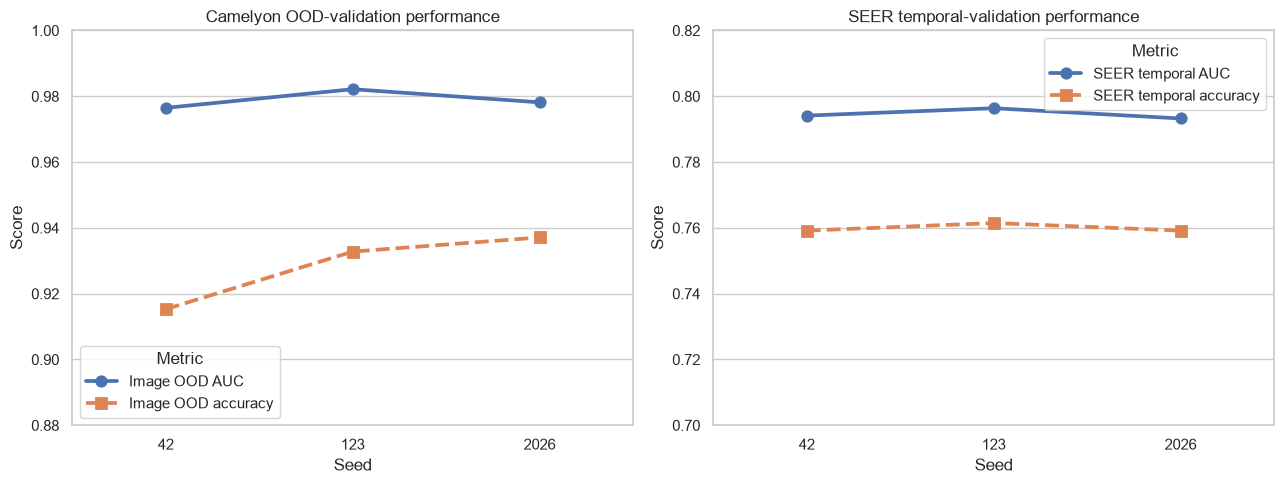

In [11]:
performance_plot = pd.DataFrame(
    {
        "Seed": seed_results["seed"].astype(str),
        "Image OOD AUC":
            seed_results["image_ood_val_roc_auc"],
        "Image OOD accuracy":
            seed_results["image_ood_val_accuracy"],
        "SEER temporal AUC":
            seed_results[
                "tabular_temporal_val_roc_auc"
            ],
        "SEER temporal accuracy":
            seed_results[
                "tabular_temporal_val_accuracy"
            ],
    }
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
)

image_plot = performance_plot.melt(
    id_vars="Seed",
    value_vars=[
        "Image OOD AUC",
        "Image OOD accuracy",
    ],
    var_name="Metric",
    value_name="Score",
)

seer_plot = performance_plot.melt(
    id_vars="Seed",
    value_vars=[
        "SEER temporal AUC",
        "SEER temporal accuracy",
    ],
    var_name="Metric",
    value_name="Score",
)

sns.pointplot(
    data=image_plot,
    x="Seed",
    y="Score",
    hue="Metric",
    markers=["o", "s"],
    linestyles=["-", "--"],
    ax=axes[0],
)
axes[0].set_ylim(0.88, 1.0)
axes[0].set_title("Camelyon OOD-validation performance")
axes[0].set_ylabel("Score")
axes[0].set_xlabel("Seed")

sns.pointplot(
    data=seer_plot,
    x="Seed",
    y="Score",
    hue="Metric",
    markers=["o", "s"],
    linestyles=["-", "--"],
    ax=axes[1],
)
axes[1].set_ylim(0.70, 0.82)
axes[1].set_title("SEER temporal-validation performance")
axes[1].set_ylabel("Score")
axes[1].set_xlabel("Seed")

plt.tight_layout()
plt.show()

## 7. Development interpretation

Across three independent seeds, the joint model achieved:

- **Camelyon OOD-validation ROC-AUC:** 0.9789 ± 0.0029
- **Camelyon OOD-validation accuracy:** 92.84% ± 1.15%
- **SEER temporal-validation ROC-AUC:** 0.7946 ± 0.0016
- **SEER temporal-validation accuracy at threshold 0.5:** 75.99% ± 0.13%

The Camelyon results show strong patch-level discrimination despite the visible hospital staining shift.

The SEER task is more difficult. Its ROC-AUC is stable across seeds, but threshold 0.5 favours N0 specificity. Selecting thresholds using internal validation increases temporal-validation N+ sensitivity from 43.96% to 74.63% and balanced accuracy from 67.13% to 71.47%.

Gradient monitoring shows mixed interaction between the two tasks. This confirms that both tasks update the shared representation, but it does not by itself prove that parameter sharing improves either task compared with separate models.

The shared trunk produces a 32-dimensional representation for both modalities. The next stage reduces these representations to eight dimensions and compares classical and hybrid quantum classifiers using identical inputs.

The Camelyon `ood_test` and SEER `temporal_test` sets remain locked. No result in this notebook is a final test result or evidence of clinical utility.